# Preenchimento por bloco de preditores de chikungunya

Este notebook avalia o preenchimento das fichas de notificação de chikungunya no nível de bloco de preditores, em vez de campo a campo.
Para os três blocos, demografia, sintomas e comorbidades, calcula a prevalência de fichas com o bloco inteiro preenchido, parcialmente preenchido, ou totalmente vazio.
Também mede a concordância entre blocos, ou seja, entre os registros com um bloco totalmente preenchido, qual fração também tem outro bloco totalmente preenchido, e resume esses padrões por ano.
Os dados de entrada já foram tratados pelo pipeline do projeto e são lidos diretamente de `data/processed/chik_treated.parquet`, sem reaplicar nenhuma etapa de limpeza aqui.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().parent.parent
RESULTS_DIR = PROJECT_ROOT / "analysis" / "results_diagnostico"
PLOTS_DIR = PROJECT_ROOT / "analysis" / "plots" / "diagnostico"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

Carrega o dataset tratado produzido pelo pipeline do projeto e organiza os preditores nos três blocos definidos pela ficha de notificação do SINAN.
Para cada bloco, calcula também, para cada ficha, o número de campos preenchidos dentro daquele bloco, que é a base de todas as análises seguintes.

In [2]:
df = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "chik_treated.parquet")

BLOCOS = {
    "demografia": [
        "CS_SEXO",
        "CS_GESTANT",
        "CS_RACA",
        "CS_ESCOL_N",
        "SG_UF",
        "IDADE_ANOS",
        "SEMANA_EPI_SIN_PRI",
    ],
    "sintomas": [
        "FEBRE",
        "MIALGIA",
        "CEFALEIA",
        "EXANTEMA",
        "VOMITO",
        "NAUSEA",
        "DOR_COSTAS",
        "CONJUNTVIT",
        "ARTRITE",
        "ARTRALGIA",
        "PETEQUIA_N",
        "LEUCOPENIA",
        "LACO",
        "DOR_RETRO",
    ],
    "comorbidades": [
        "DIABETES",
        "HEMATOLOG",
        "HEPATOPAT",
        "RENAL",
        "HIPERTENSA",
        "ACIDO_PEPT",
        "AUTO_IMUNE",
    ],
}

num_preenchidos_por_bloco = pd.DataFrame(
    {nome_bloco: df[colunas].notna().sum(axis=1) for nome_bloco, colunas in BLOCOS.items()}
)
tamanho_por_bloco = {nome_bloco: len(colunas) for nome_bloco, colunas in BLOCOS.items()}
tamanho_por_bloco

{'demografia': 7, 'sintomas': 14, 'comorbidades': 7}

Classifica cada ficha, para cada bloco, em três categorias, bloco totalmente preenchido, bloco parcialmente preenchido, e bloco totalmente vazio.
Calcula a prevalência de cada categoria em cada bloco e salva o resultado em `analysis/results_diagnostico/prevalencia_preenchimento_por_bloco.csv`, com um gráfico de barras empilhadas em `analysis/plots/diagnostico/prevalencia_preenchimento_por_bloco.png`.

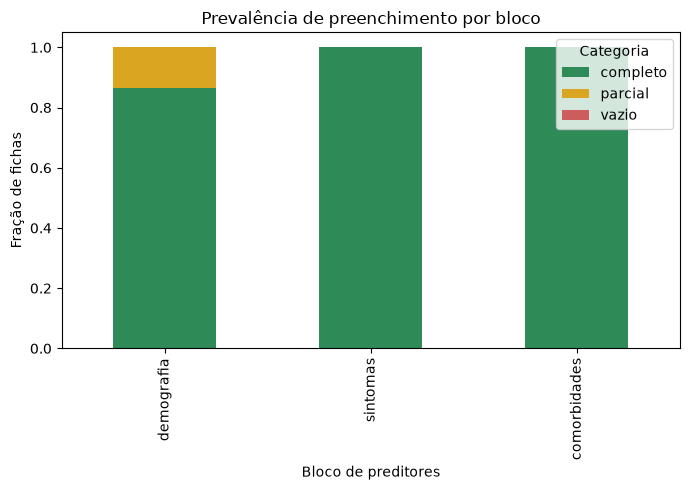

,completo,parcial,vazio
demografia,0.864211,0.135789,0.0
sintomas,1.000000,0.000000,0.0
comorbidades,1.000000,0.000000,0.0


In [3]:
def classificar_bloco(num_preenchidos, tamanho_bloco):
    if num_preenchidos == tamanho_bloco:
        return "completo"
    if num_preenchidos == 0:
        return "vazio"
    return "parcial"


categoria_por_bloco = pd.DataFrame(
    {
        nome_bloco: num_preenchidos_por_bloco[nome_bloco].apply(
            lambda valor: classificar_bloco(valor, tamanho_por_bloco[nome_bloco])
        )
        for nome_bloco in BLOCOS
    }
)

prevalencia_preenchimento_por_bloco = (
    categoria_por_bloco.apply(lambda coluna: coluna.value_counts(normalize=True))
    .reindex(["completo", "parcial", "vazio"])
    .fillna(0.0)
    .T
)
prevalencia_preenchimento_por_bloco.to_csv(RESULTS_DIR / "prevalencia_preenchimento_por_bloco.csv")

figura, eixo = plt.subplots(figsize=(7, 5))
prevalencia_preenchimento_por_bloco[["completo", "parcial", "vazio"]].plot(
    kind="bar", stacked=True, ax=eixo, color=["seagreen", "goldenrod", "indianred"]
)
eixo.set_ylabel("Fração de fichas")
eixo.set_xlabel("Bloco de preditores")
eixo.set_title("Prevalência de preenchimento por bloco")
eixo.legend(title="Categoria")
figura.tight_layout()
figura.savefig(PLOTS_DIR / "prevalencia_preenchimento_por_bloco.png", dpi=150)
plt.show()

prevalencia_preenchimento_por_bloco

Mede a concordância entre blocos, definida como, entre os registros em que um bloco de referência está totalmente preenchido, qual fração também tem cada um dos outros blocos totalmente preenchido.
O resultado é uma matriz de concordância, salva em `analysis/results_diagnostico/concordancia_entre_blocos.csv`, em que a linha indica o bloco de referência e a coluna indica o bloco comparado.

In [4]:
bloco_completo = categoria_por_bloco == "completo"

matriz_concordancia = pd.DataFrame(index=BLOCOS.keys(), columns=BLOCOS.keys(), dtype=float)
for bloco_referencia in BLOCOS:
    subconjunto = bloco_completo.loc[bloco_completo[bloco_referencia]]
    for bloco_comparado in BLOCOS:
        matriz_concordancia.loc[bloco_referencia, bloco_comparado] = subconjunto[bloco_comparado].mean()

matriz_concordancia.to_csv(RESULTS_DIR / "concordancia_entre_blocos.csv")
matriz_concordancia

,demografia,sintomas,comorbidades
demografia,1.000000,1.0,1.0
sintomas,0.864211,1.0,1.0
comorbidades,0.864211,1.0,1.0


Resume a prevalência de preenchimento de cada bloco por ano de notificação, para verificar se o padrão de preenchimento em nível de bloco mudou entre 2020 e 2025.
Como os blocos de sintomas e comorbidades não têm nenhum campo ausente em nenhum registro, a variação ao longo dos anos, quando existir, está concentrada no bloco de demografia.
O resultado é salvo em `analysis/results_diagnostico/prevalencia_preenchimento_por_bloco_e_ano.csv` e o gráfico de linhas, apenas para a categoria completo, em `analysis/plots/diagnostico/prevalencia_bloco_completo_por_ano.png`.

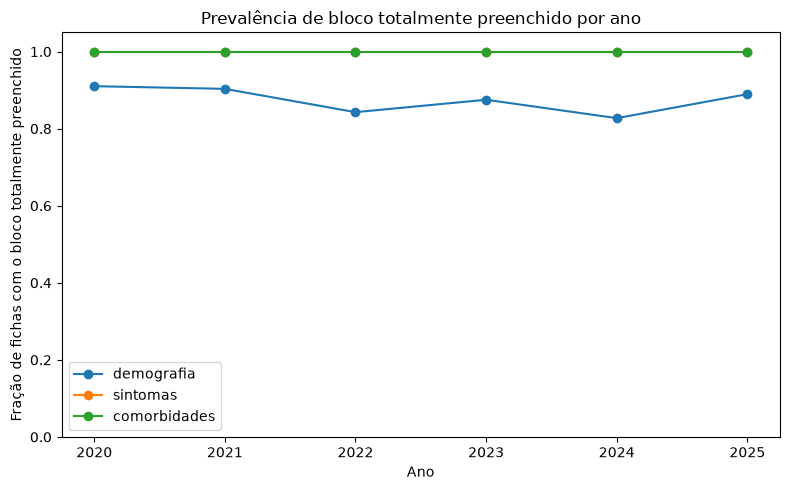

bloco,comorbidades,demografia,sintomas
year,,,
2020,1.0,0.910256,1.0
2021,1.0,0.903328,1.0
2022,1.0,0.842812,1.0
2023,1.0,0.875051,1.0
2024,1.0,0.827300,1.0
2025,1.0,0.889540,1.0


In [5]:
categoria_por_bloco_com_ano = categoria_por_bloco.copy()
categoria_por_bloco_com_ano["year"] = df["year"]

prevalencia_por_bloco_e_ano = []
for nome_bloco in BLOCOS:
    tabela_ano = (
        categoria_por_bloco_com_ano.groupby("year")[nome_bloco]
        .value_counts(normalize=True)
        .rename("fracao")
        .reset_index()
    )
    tabela_ano["bloco"] = nome_bloco
    tabela_ano = tabela_ano.rename(columns={nome_bloco: "categoria"})
    prevalencia_por_bloco_e_ano.append(tabela_ano)

prevalencia_por_bloco_e_ano = pd.concat(prevalencia_por_bloco_e_ano, ignore_index=True)
prevalencia_por_bloco_e_ano.to_csv(RESULTS_DIR / "prevalencia_preenchimento_por_bloco_e_ano.csv", index=False)

fracao_completo_por_ano = prevalencia_por_bloco_e_ano[
    prevalencia_por_bloco_e_ano["categoria"] == "completo"
].pivot(index="year", columns="bloco", values="fracao")

figura, eixo = plt.subplots(figsize=(8, 5))
for nome_bloco in BLOCOS:
    eixo.plot(fracao_completo_por_ano.index, fracao_completo_por_ano[nome_bloco], marker="o", label=nome_bloco)
eixo.set_xlabel("Ano")
eixo.set_ylabel("Fração de fichas com o bloco totalmente preenchido")
eixo.set_title("Prevalência de bloco totalmente preenchido por ano")
eixo.set_ylim(0, 1.05)
eixo.legend()
figura.tight_layout()
figura.savefig(PLOTS_DIR / "prevalencia_bloco_completo_por_ano.png", dpi=150)
plt.show()

fracao_completo_por_ano

## Síntese dos achados

Os blocos de sintomas e de comorbidades estão totalmente preenchidos em 100 por cento das fichas, e nenhuma ficha tem esses blocos parcialmente preenchidos ou totalmente vazios.
Já o bloco de demografia está totalmente preenchido em cerca de 86,4 por cento das fichas, e parcialmente preenchido nos 13,6 por cento restantes, refletindo a ausência isolada do campo de escolaridade discutida no notebook de ausência por preditor.
Nenhum bloco tem fichas totalmente vazias, ou seja, não há caso em que todos os campos de um bloco estejam ausentes ao mesmo tempo.

A matriz de concordância confirma esse padrão.
Entre as fichas com o bloco de sintomas ou o bloco de comorbidades totalmente preenchido, que é a totalidade das fichas, 86,4 por cento também têm o bloco de demografia totalmente preenchido, o mesmo valor da prevalência geral do bloco de demografia.
Entre as fichas com o bloco de demografia totalmente preenchido, 100 por cento também têm os blocos de sintomas e de comorbidades totalmente preenchidos, já que esses dois blocos são sempre completos.

A prevalência de bloco totalmente preenchido por ano mostra que sintomas e comorbidades permanecem em 100 por cento em todos os anos de 2020 a 2025.
A prevalência do bloco de demografia completo varia de ano a ano, entre aproximadamente 82,7 por cento em 2024 e 91,0 por cento em 2020, sem uma tendência monotônica clara de melhora ou piora ao longo do período.

Em conjunto, esses resultados indicam que o único padrão de incompletude em nível de bloco neste dataset vem do bloco de demografia, e especificamente do campo de escolaridade, enquanto os blocos de sintomas e comorbidades podem ser tratados como efetivamente completos para fins de modelagem.